# Cross-Dataset Notebook 02 — Feature Semantics Verification

**Research:** Lightweight Network-Flow APT Detection for IIoT Edge Gateways  
**Datasets:** X-IIoTID Core19 and ToN-IoT Core10; Edge-IIoTset assessed separately.  
**Inputs:** Saved feature-quality audits, Notebook 01 mapping, and **frozen TRAIN CSV.GZ files only**.  
**Outputs:** Three small audit CSVs, one JSON decision report, and one missingness figure.

**Safety / science:** No model training, no resplitting, no editing input datasets, **no validation/test rows opened**, no automatic approval of cross-dataset transfer. All training rows are inspected (no sampling). This is an exploratory **evidence check**, not proof of true semantic equivalence.

Simple meaning: `Scr_bytes` and `src_bytes` sound similar, but may count different bytes. We compare the evidence before choosing a shared representation.

## 1 — Load existing audits and define the ten candidate mappings

All names and report locations match your Notebook 01. You can open this notebook from anywhere inside your repository. It should locate `network_flow_v2` automatically.

In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate your actual project. The Windows fallback matches your current repo.
search_starts = [Path.cwd(), *Path.cwd().parents,
                 Path(r'D:\J26-CS-336-Network-Flow-V2\network_flow_v2')]
ROOT = None
for start in search_starts:
    choice = start if start.name == 'network_flow_v2' else start / 'network_flow_v2'
    if (choice / 'reports/audits/x_iiotid_v3_feature_quality.json').is_file():
        ROOT = choice
        break
if ROOT is None:
    raise FileNotFoundError('Cannot locate network_flow_v2. Open the repo in VS Code or update search_starts.')

AUDITS = ROOT / 'reports' / 'audits'
METRICS = ROOT / 'reports' / 'metrics'
FIGURES = ROOT / 'reports' / 'figures'
NOTEBOOK01 = AUDITS / 'cross_dataset_v3_feature_compatibility.json'
if not NOTEBOOK01.is_file():
    raise FileNotFoundError(f'Run Cross-Dataset Notebook 01 first: {NOTEBOOK01}')

mapping_report = json.loads(NOTEBOOK01.read_text(encoding='utf-8'))
if mapping_report.get('mapping_count') != 10 or mapping_report.get('approval') != 'NOT_APPROVED_FOR_TRANSFER':
    raise ValueError('Notebook 01 mapping changed: review before continuing.')
mapping = pd.DataFrame(mapping_report['candidate_mappings'])
needed = {'concept','x_iiotid_column','ton_iot_column','kind'}
if not needed.issubset(mapping.columns) or len(mapping) != 10:
    raise ValueError('Expected the 10 approved-for-audit *candidates* from Notebook 01.')
if mapping['concept'].duplicated().any():
    raise ValueError('Duplicate concept identifiers.')

meta = {}
for name in ('x_iiotid', 'ton_iot'):
    audit = AUDITS / f'{name}_v3_feature_quality.json'
    split = AUDITS / f'{name}_v3_split_report.json'
    if not audit.is_file() or not split.is_file():
        raise FileNotFoundError(f'Missing saved audit / split report for {name}.')
    meta[name] = {
        'quality': json.loads(audit.read_text(encoding='utf-8')),
        'split': json.loads(split.read_text(encoding='utf-8')),
    }

for row in mapping.itertuples():
    if row.x_iiotid_column not in meta['x_iiotid']['quality']['selected_features']:
        raise ValueError(f'Unknown X-IIoTID column: {row.x_iiotid_column}')
    if row.ton_iot_column not in meta['ton_iot']['quality']['selected_features']:
        raise ValueError(f'Unknown ToN-IoT column: {row.ton_iot_column}')

print('Project:', ROOT)
print('Candidate concepts:', len(mapping), '| Semantically verified: 0')
print('Read-only TRAIN partition audit. No validation or test input will be opened.')
display(mapping[['concept','x_iiotid_column','ton_iot_column','kind']])

Project: d:\J26-CS-336-Network-Flow-V2\network_flow_v2
Candidate concepts: 10 | Semantically verified: 0
Read-only TRAIN partition audit. No validation or test input will be opened.


,concept,x_iiotid_column,ton_iot_column,kind
0,protocol,Protocol,proto,categorical
1,service,Service,service,categorical
2,flow_duration,Duration,duration,numeric
3,source_payload_bytes,Scr_bytes,src_bytes,numeric
4,destination_payload_bytes,Des_bytes,dst_bytes,numeric
5,connection_state,Conn_state,conn_state,categorical
6,source_packets,Scr_pkts,src_pkts,numeric
7,source_ip_bytes,Scr_ip_bytes,src_ip_bytes,numeric
8,destination_packets,Des_pkts,dst_pkts,numeric
9,destination_ip_bytes,Des_ip_bytes,dst_ip_bytes,numeric


## 2 — Find only the saved frozen TRAIN partitions

Folder layouts can differ after reorganizing your repository. We accept only the exact frozen `*_train_v3.csv.gz` filenames and **refuse ambiguous duplicates**. We also check the expected training counts from the saved split reports.

In [2]:
def find_one_train_file(dataset, filename):
    candidates = [ROOT / 'data' / 'splits' / dataset / filename,
                  ROOT / 'data' / 'splits' / filename]
    existing = [p for p in candidates if p.is_file()]
    if len(existing) != 1:
        raise FileNotFoundError(
            f'Expected exactly one train file for {dataset}; found {len(existing)}: {existing}. '
            'Resolve ambiguous or missing training paths without changing the frozen files.'
        )
    return existing[0]

TRAIN_PATHS = {
    'x_iiotid': find_one_train_file('x_iiotid', 'x_iiotid_core19_train_v3.csv.gz'),
    'ton_iot': find_one_train_file('ton_iot', 'ton_iot_core10_train_v3.csv.gz'),
}
EXPECTED_TRAIN_ROWS = {'x_iiotid': 574585, 'ton_iot': 147730}
CHUNK_SIZE = 50000
ABSENT = frozenset(('', '-', '?', 'na', 'n/a', 'nan', 'null', 'none', 'missing', '(empty)', '(null)'))

specs = {}
for dataset in TRAIN_PATHS:
    col = 'x_iiotid_column' if dataset == 'x_iiotid' else 'ton_iot_column'
    columns = mapping[col].tolist()
    train_path = TRAIN_PATHS[dataset]
    header = pd.read_csv(train_path, nrows=0).columns.tolist()  # header ONLY
    missing = [x for x in columns if x not in header]
    if missing:
        raise ValueError(f'{dataset} training file does not contain {missing}')
    label = 'class3' if dataset == 'x_iiotid' else 'label'
    if label in columns:
        raise AssertionError('Labels must never be used as candidate features.')
    if dataset == 'x_iiotid':
        reported = meta[dataset]['split']['counts']['train']
    else:
        reported = meta[dataset]['split']['counts']['train']['rows']
    if int(reported) != EXPECTED_TRAIN_ROWS[dataset]:
        raise ValueError(f'{dataset}: expected train size differs from frozen split report.')
    specs[dataset] = {'file':train_path, 'features':columns, 'column_key':col}
    print(dataset, '|', train_path, '| expected TRAIN rows:', reported)

x_iiotid | d:\J26-CS-336-Network-Flow-V2\network_flow_v2\data\splits\x_iiotid\x_iiotid_core19_train_v3.csv.gz | expected TRAIN rows: 574585
ton_iot | d:\J26-CS-336-Network-Flow-V2\network_flow_v2\data\splits\ton_iot\ton_iot_core10_train_v3.csv.gz | expected TRAIN rows: 147730


## 3 — Inspect every training row, without loading the whole table into memory

For each candidate feature, we measure missing/placeholder values and either numeric ranges or category frequencies. Numeric quantiles use **all valid TRAIN values** (not a sample). We also check contradictions such as negative packet counts and IP byte totals smaller than payload bytes. **A plausible numerical range does not establish identical units or meanings.**

In [3]:
# Small counters plus arrays of genuine numeric TRAIN values for exact quantiles.
NUMERIC = set(mapping.loc[mapping.kind.eq('numeric'), 'concept'])
CATEGORICAL = set(mapping.loc[mapping.kind.eq('categorical'), 'concept'])
lookup = {dataset: dict(zip(mapping['concept'], mapping[specs[dataset]['column_key']]))
          for dataset in specs}

stats = {}
sanity = {}
row_counts = {}

for dataset, spec in specs.items():
    this = {}
    for concept in mapping.concept:
        this[concept] = {
            'count': 0, 'missing': 0, 'invalid': 0, 'negative': 0,
            'zero': 0, 'noninteger': 0, 'numbers': [], 'categories': Counter(),
            'raw_examples': {},
        }
    pairs = {direction:{'both_valid':0, 'ip_lt_payload':0,
                        'ip_positive_packet_zero':0, 'pkt_valid':0}
             for direction in ('source','destination')}
    rows_seen = 0
    for chunk in pd.read_csv(spec['file'], usecols=spec['features'], dtype=str,
                             keep_default_na=False, chunksize=CHUNK_SIZE):
        rows_seen += len(chunk)
        numeric_values = {}
        for concept, column in lookup[dataset].items():
            entry = this[concept]
            raw = chunk[column].astype('string').str.strip()
            normalized = raw.str.lower()
            absent = normalized.isin(ABSENT).fillna(True)
            entry['count'] += len(raw)
            entry['missing'] += int(absent.sum())
            if concept in NUMERIC:
                numbers = pd.to_numeric(raw.mask(absent), errors='coerce')
                finite = np.isfinite(numbers.to_numpy(dtype='float64', na_value=np.nan))
                valid = (~absent.to_numpy(dtype=bool)) & finite
                entry['invalid'] += int((~absent.to_numpy(dtype=bool) & ~finite).sum())
                arr = numbers.to_numpy(dtype='float64', na_value=np.nan)
                good = arr[valid]
                if len(good):
                    entry['numbers'].append(good)
                    entry['negative'] += int((good < 0).sum())
                    entry['zero'] += int((good == 0).sum())
                    if concept not in ('flow_duration',):
                        entry['noninteger'] += int((np.mod(good, 1) != 0).sum())
                numeric_values[concept] = arr
            else:
                present = normalized.loc[~absent].fillna('')
                entry['categories'].update(present.tolist())
                # Preserve a raw example per normalized value; not just inferred mappings.
                for norm, original in zip(present.iloc[:1000], raw.loc[~absent].iloc[:1000]):
                    if norm not in entry['raw_examples']:
                        entry['raw_examples'][norm] = str(original)[:75]

        for direction in ('source', 'destination'):
            payload = numeric_values[f'{direction}_payload_bytes']
            ip_bytes = numeric_values[f'{direction}_ip_bytes']
            pkts = numeric_values[f'{direction}_packets']
            both = np.isfinite(payload) & np.isfinite(ip_bytes)
            pairs[direction]['both_valid'] += int(both.sum())
            pairs[direction]['ip_lt_payload'] += int((both & (ip_bytes < payload)).sum())
            pkts_valid = np.isfinite(pkts) & np.isfinite(ip_bytes)
            pairs[direction]['pkt_valid'] += int(pkts_valid.sum())
            pairs[direction]['ip_positive_packet_zero'] += int(
                (pkts_valid & (pkts == 0) & (ip_bytes > 0)).sum()
            )
    if rows_seen != EXPECTED_TRAIN_ROWS[dataset]:
        raise ValueError(f'{dataset}: expected {EXPECTED_TRAIN_ROWS[dataset]} TRAIN rows; read {rows_seen}.')
    row_counts[dataset] = rows_seen
    stats[dataset] = this
    sanity[dataset] = pairs
    print(f'{dataset}: all {rows_seen:,} TRAIN rows checked; no other partitions opened.')

x_iiotid: all 574,585 TRAIN rows checked; no other partitions opened.
ton_iot: all 147,730 TRAIN rows checked; no other partitions opened.


## 4 — Numeric checks: ranges, missingness and impossible values

- A *missing value* means a value was not recorded; it is **not** automatically a zero.
- *Invalid numeric* means a non-missing value cannot be interpreted as a finite number.
- `p50` is the median; `p95` is the value at the 95th percentile.
- Negative bytes, packets and durations are potential data-quality problems, not automatic label leakage.

In [4]:
numeric_rows = []
for dataset in specs:
    for concept in mapping.concept:
        if concept not in NUMERIC:
            continue
        entry = stats[dataset][concept]
        arrays = entry.pop('numbers')  # Free these arrays after exact summary.
        arr = np.concatenate(arrays) if arrays else np.empty(0, dtype=np.float64)
        rec = {
            'dataset':dataset, 'concept':concept, 'column':lookup[dataset][concept],
            'train_rows':row_counts[dataset], 'valid_numeric':len(arr),
            'missing_or_placeholder':entry['missing'],
            'missing_pct':round(100*entry['missing']/row_counts[dataset],3),
            'invalid_numeric':entry['invalid'], 'negative':entry['negative'],
            'zero':entry['zero'], 'fractional_count_value':entry['noninteger'],
        }
        for percentile, name in ((0,'min'),(25,'p25'),(50,'p50'),(95,'p95'),(99,'p99'),(100,'max')):
            rec[name] = float(np.percentile(arr, percentile)) if len(arr) else None
        numeric_rows.append(rec)
        del arr
numeric_df = pd.DataFrame(numeric_rows)
display(numeric_df[['dataset','concept','missing_pct','invalid_numeric','negative','p50','p95','max']])
print('Important: very different distributions may be caused by traffic mix, not necessarily unit mismatch.')
print('Sanity checks: IP bytes lower than payload bytes (under joint valid observations):')
display(pd.DataFrame([{'dataset':dataset,'direction':direction, **info}
                      for dataset,dirs in sanity.items() for direction,info in dirs.items()]))

,dataset,concept,missing_pct,invalid_numeric,negative,p50,p95,max
0,x_iiotid,flow_duration,12.007,0,0,0.025822,42.757091,9.331420e+03
1,x_iiotid,source_payload_bytes,29.396,0,0,156.000000,7534.050000,9.262400e+05
2,x_iiotid,destination_payload_bytes,29.396,0,0,72.000000,541824.650000,1.935968e+07
3,x_iiotid,source_packets,17.587,0,0,2.000000,153.000000,6.553900e+04
4,x_iiotid,source_ip_bytes,17.587,1,0,590.000000,15968.200000,4.194444e+06
5,x_iiotid,destination_packets,17.587,0,0,1.000000,223.000000,6.557000e+04
6,x_iiotid,destination_ip_bytes,17.587,0,0,71.000000,164765.300000,2.011009e+07
7,ton_iot,flow_duration,0.000,0,0,0.000019,1.287052,9.351693e+04
8,ton_iot,source_payload_bytes,0.000,0,0,0.000000,239.000000,1.430386e+09
9,ton_iot,destination_payload_bytes,0.000,0,0,0.000000,1919.000000,3.392679e+09


Important: very different distributions may be caused by traffic mix, not necessarily unit mismatch.
Sanity checks: IP bytes lower than payload bytes (under joint valid observations):


,dataset,direction,both_valid,ip_lt_payload,ip_positive_packet_zero,pkt_valid
0,x_iiotid,source,405679,8,0,473529
1,x_iiotid,destination,405680,63,0,473530
2,ton_iot,source,147730,328,0,147730
3,ton_iot,destination,147730,585,0,147730


## 5 — Categorical checks: actual category encodings and missingness

We compare **lowercased strings for audit only**. This is **not** a verified category mapping. In particular, X-IIoTID `Conn_state` may use summarized numeric states while Zeek uses symbolic connection-state codes such as `SF`, `S0` and `REJ`.

In [5]:
categorical_rows = []
cat_sets = {}
for dataset in specs:
    for concept in mapping.concept:
        if concept not in CATEGORICAL:
            continue
        entry = stats[dataset][concept]
        counts = entry['categories']
        cat_sets[(dataset,concept)] = set(counts)
        categorical_rows.append({
            'dataset':dataset,'concept':concept,'column':lookup[dataset][concept],
            'train_rows':row_counts[dataset],
            'missing_or_placeholder':entry['missing'],
            'missing_pct':round(100*entry['missing']/row_counts[dataset],3),
            'distinct_categories':len(counts),
            'top_categories':'; '.join(f'{str(k)[:35]}:{v}' for k,v in counts.most_common(10)),
        })
categorical_df = pd.DataFrame(categorical_rows)
display(categorical_df)

for concept in sorted(CATEGORICAL):
    left=cat_sets[('x_iiotid',concept)]
    right=cat_sets[('ton_iot',concept)]
    shared=left.intersection(right)
    print(f'{concept}: X {len(left)} categories, ToN {len(right)}; exact lowercased overlaps {len(shared)}')
    print('  shared examples:', sorted(shared)[:12])
    if concept == 'connection_state':
        print('  WARNING: Matching names without a state-code translation is unsafe.')

,dataset,concept,column,train_rows,missing_or_placeholder,missing_pct,distinct_categories,top_categories
0,x_iiotid,protocol,Protocol,574585,154,0.027,3,udp:295600; tcp:277134; icmp:1697
1,x_iiotid,service,Service,574585,0,0.000,17,http:166505; dns:155699; coap:136142; websocke...
2,x_iiotid,connection_state,Conn_state,574585,0,0.000,2,1:506799; 0:67786
3,ton_iot,protocol,proto,147730,0,0.000,3,tcp:118590; udp:28943; icmp:197
4,ton_iot,service,service,147730,107589,72.828,8,dns:26816; http:12289; ssl:340; ftp:339; gssap...
5,ton_iot,connection_state,conn_state,147730,0,0.000,13,s0:41341; rej:37716; oth:22922; sf:18528; sh:1...


connection_state: X 2 categories, ToN 13; exact lowercased overlaps 0
  shared examples: []
protocol: X 3 categories, ToN 3; exact lowercased overlaps 3
  shared examples: ['icmp', 'tcp', 'udp']
service: X 17 categories, ToN 8; exact lowercased overlaps 2
  shared examples: ['dns', 'http']


## 6 — Review the published field definitions

Source descriptions are useful evidence, but they **cannot be proven equivalent by inspecting numeric distributions**.

- **X-IIoTID** paper lists `Duration` as the interval between first and last packets; `Scr_bytes` / `Des_bytes` as source/destination bytes; `Conn_state` as a summarized connection status. Its IP-byte fields describe values from the IP total-length header. [X-IIoTID paper](https://www.researchgate.net/publication/353673359_X-IIoTID_A_Connectivity-Agnostic_and_Device-Agnostic_Intrusion_Data_Set_for_Industrial_Internet_of_Things/download); [official dataset README](https://github.com/Alhawawreh/X-IIoTID).
- **ToN-IoT** network logs originate from Zeek and PCAP-derived sources. [UNSW official dataset description](https://research.unsw.edu.au/projects/toniot-datasets).
- **Zeek** `orig_bytes` / `resp_bytes` denote **payload bytes**, `orig_ip_bytes` / `resp_ip_bytes` denote IP-level byte counts, and `conn_state` uses symbolic codes. Zeek's duration excludes some trailing nonproductive TCP packets. [Zeek official reference](https://docs.zeek.org/en/lts/scripts/base/protocols/conn/main.zeek.html).

**Consequence:** Some pairs could be compatible with documented transformations, but the published descriptions do **not yet justify a blanket rename-and-merge**. The exact ToN-IoT CSV export lineage and the X-IIoTID source/response orientation still require verification.

## 7 — Make a cautious evidence table (no automatic semantic approval)

`NOT_VERIFIED` means **not ready to train a cross-dataset model**. A mismatch is a useful research finding, not a failure. Category overlap and similar p95 values are diagnostic clues only.

In [6]:
risks = {
    'protocol': ('CHECK_CATEGORY_ENCODING', 'Likely network protocol, but text/codes/unknown tokens may differ.'),
    'service': ('CHECK_SERVICE_DEFINITION_AND_MISSINGNESS', 'Destination-port service vs Zeek detected service can differ; placeholders can dominate.'),
    'flow_duration': ('CHECK_DURATION_RULE', 'X first-to-last packet vs Zeek productive-traffic duration; semantics may differ.'),
    'source_payload_bytes': ('CHECK_BYTE_DEFINITION', 'X source bytes not conclusively payload bytes; Zeek orig_bytes is payload.'),
    'destination_payload_bytes': ('CHECK_BYTE_DEFINITION', 'X destination bytes not conclusively payload bytes; Zeek resp_bytes is payload.'),
    'connection_state': ('NEEDS_EXPLICIT_STATE_MAPPING', 'X summary states may use 1/2/3; Zeek states include SF/S0/REJ.'),
    'source_packets': ('CHECK_PACKET_DIRECTION', 'Confirm source means Zeek originator; packet-counting rules also matter.'),
    'source_ip_bytes': ('CHECK_IP_TOTAL_LENGTH_AND_DIRECTION', 'Both may use IP total_length; confirm direction and missing conventions.'),
    'destination_packets': ('CHECK_PACKET_DIRECTION', 'Confirm destination means Zeek responder; packet-counting rules matter.'),
    'destination_ip_bytes': ('CHECK_IP_TOTAL_LENGTH_AND_DIRECTION', 'Both may use IP total_length; confirm direction and missing conventions.'),
}

review = []
for row in mapping.itertuples():
    concept = row.concept
    xs = stats['x_iiotid'][concept]
    ts = stats['ton_iot'][concept]
    kind = row.kind
    issue, explanation = risks[concept]
    if kind == 'categorical':
        xset = cat_sets[('x_iiotid',concept)]
        tset = cat_sets[('ton_iot',concept)]
        shared = len(xset & tset)
        mismatch = (concept == 'connection_state' and shared == 0)
        observed = f'lowercase_category_overlap={shared}; X={len(xset)}, ToN={len(tset)}'
        if mismatch:
            issue = 'OBSERVED_STATE_ENCODING_MISMATCH'
    else:
        xn = numeric_df[(numeric_df.dataset=='x_iiotid') & (numeric_df.concept==concept)].iloc[0]
        tn = numeric_df[(numeric_df.dataset=='ton_iot') & (numeric_df.concept==concept)].iloc[0]
        observed = (f'X_p50={xn.p50}; ToN_p50={tn.p50}; '
                    f'X_invalid={xn.invalid_numeric}; ToN_invalid={tn.invalid_numeric}')
    review.append({
        'concept':concept, 'x_iiotid_column':row.x_iiotid_column,
        'ton_iot_column':row.ton_iot_column, 'kind':kind,
        'x_missing_pct':round(100*xs['missing']/row_counts['x_iiotid'],3),
        'ton_missing_pct':round(100*ts['missing']/row_counts['ton_iot'],3),
        'flag':issue, 'explanation':explanation, 'training_observation':observed,
        'same_meaning_verified':False, 'same_units_verified':False,
        'source_direction_verified':False, 'gateway_extractable_verified':False,
        'transfer_status':'NOT_VERIFIED',
    })
review_df = pd.DataFrame(review)
display(review_df[['concept','x_missing_pct','ton_missing_pct','flag','transfer_status']])
print('Automatically approved transfer features:', int(review_df.same_meaning_verified.sum()))
print('Decision: hold model transfer until source semantics and category transformations are documented.')

,concept,x_missing_pct,ton_missing_pct,flag,transfer_status
0,protocol,0.027,0.000,CHECK_CATEGORY_ENCODING,NOT_VERIFIED
1,service,0.000,72.828,CHECK_SERVICE_DEFINITION_AND_MISSINGNESS,NOT_VERIFIED
2,flow_duration,12.007,0.000,CHECK_DURATION_RULE,NOT_VERIFIED
3,source_payload_bytes,29.396,0.000,CHECK_BYTE_DEFINITION,NOT_VERIFIED
4,destination_payload_bytes,29.396,0.000,CHECK_BYTE_DEFINITION,NOT_VERIFIED
5,connection_state,0.000,0.000,OBSERVED_STATE_ENCODING_MISMATCH,NOT_VERIFIED
6,source_packets,17.587,0.000,CHECK_PACKET_DIRECTION,NOT_VERIFIED
7,source_ip_bytes,17.587,0.000,CHECK_IP_TOTAL_LENGTH_AND_DIRECTION,NOT_VERIFIED
8,destination_packets,17.587,0.000,CHECK_PACKET_DIRECTION,NOT_VERIFIED
9,destination_ip_bytes,17.587,0.000,CHECK_IP_TOTAL_LENGTH_AND_DIRECTION,NOT_VERIFIED


Automatically approved transfer features: 0
Decision: hold model transfer until source semantics and category transformations are documented.


## 8 — Plot training-data missingness (not prediction performance)

A high missingness rate can make a field an unreliable cross-dataset input even when names agree. This chart shows only TRAIN inputs.

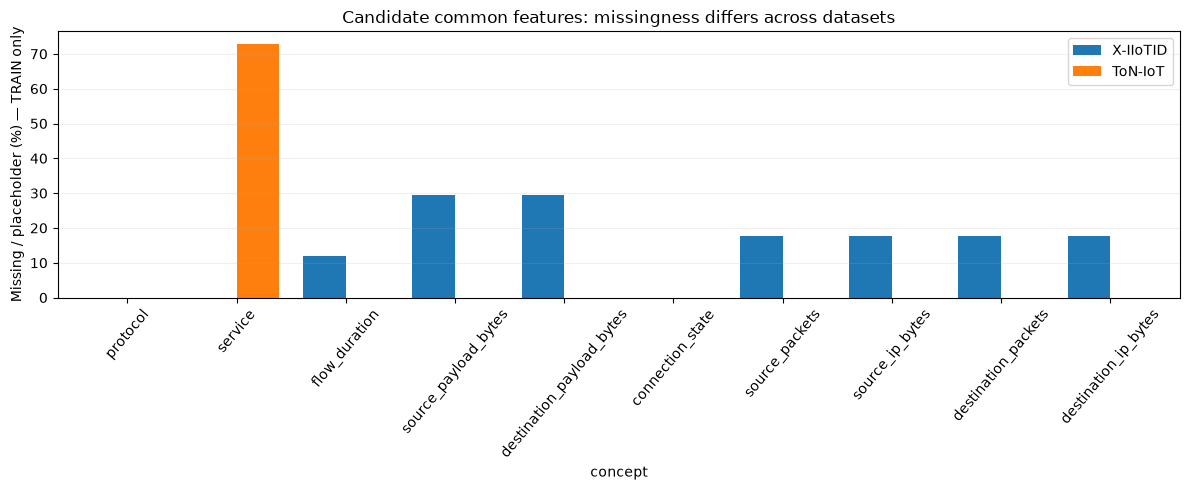

In [7]:
plot_data = review_df.set_index('concept')[['x_missing_pct','ton_missing_pct']]
ax = plot_data.plot.bar(figsize=(12,5), width=0.78)
ax.set_ylabel('Missing / placeholder (%) — TRAIN only')
ax.set_title('Candidate common features: missingness differs across datasets')
ax.set_ylim(bottom=0)
ax.tick_params(axis='x', labelrotation=50)
ax.grid(axis='y', alpha=.18)
ax.legend(['X-IIoTID', 'ToN-IoT'])
plt.tight_layout()
plt.show()

## 9 — Save small audit outputs

This cell **only creates/replaces these five files under `reports/`**:

1. `reports/metrics/cross_dataset_v3_semantics_numeric_train.csv`
2. `reports/metrics/cross_dataset_v3_semantics_categorical_train.csv`
3. `reports/metrics/cross_dataset_v3_semantics_mapping.csv`
4. `reports/audits/cross_dataset_v3_feature_semantics_verification.json`
5. `reports/figures/cross_dataset_v3_semantics_missingness.png`

No raw, processed, split, Excel, trained-model, or test files are modified.

In [8]:
METRICS.mkdir(parents=True, exist_ok=True)
AUDITS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

numeric_csv = METRICS / 'cross_dataset_v3_semantics_numeric_train.csv'
categorical_csv = METRICS / 'cross_dataset_v3_semantics_categorical_train.csv'
review_csv = METRICS / 'cross_dataset_v3_semantics_mapping.csv'
report_json = AUDITS / 'cross_dataset_v3_feature_semantics_verification.json'
figure_png = FIGURES / 'cross_dataset_v3_semantics_missingness.png'

numeric_df.to_csv(numeric_csv, index=False)
categorical_df.to_csv(categorical_csv, index=False)
review_df.to_csv(review_csv, index=False)

fig, ax = plt.subplots(figsize=(12,5))
plot_data.plot.bar(ax=ax, width=0.78)
ax.set_ylabel('Missing / placeholder (%) — TRAIN only')
ax.set_title('X-IIoTID vs ToN-IoT: candidate-feature missingness')
ax.tick_params(axis='x', labelrotation=50)
ax.grid(axis='y', alpha=.18)
ax.legend(['X-IIoTID','ToN-IoT'])
fig.tight_layout()
fig.savefig(figure_png, dpi=150, bbox_inches='tight')
plt.close(fig)

def sha256_file(path):
    hasher = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024*1024), b''):
            hasher.update(block)
    return hasher.hexdigest()

report = {
    'notebook':'02_feature_semantics_verification.ipynb',
    'timestamp_utc':datetime.now(timezone.utc).isoformat(),
    'purpose':'Read-only TRAIN feature semantics screening (not model transfer)',
    'source_training_files':{
        name:{'path_relative_to_root':str(specs[name]['file'].relative_to(ROOT)),
              'sha256':sha256_file(specs[name]['file']),
              'train_rows_scanned':row_counts[name]}
        for name in specs
    },
    'candidate_count':int(len(mapping)),
    'semantically_verified_count':0,
    'decision':'NOT_APPROVED_FOR_TRANSFER',
    'evidence_limited_to':'existing feature audits, mapping report, documented feature descriptions, full TRAIN records',
    'training_sanity_checks':sanity,
    'candidate_review':review_df.to_dict(orient='records'),
    'references':{
        'X_IIoTID_paper':'https://www.researchgate.net/publication/353673359_X-IIoTID_A_Connectivity-Agnostic_and_Device-Agnostic_Intrusion_Data_Set_for_Industrial_Internet_of_Things/download',
        'X_IIoTID_repository':'https://github.com/Alhawawreh/X-IIoTID',
        'ToN_IoT_UNSW':'https://research.unsw.edu.au/projects/toniot-datasets',
        'Zeek_fields':'https://docs.zeek.org/en/lts/scripts/base/protocols/conn/main.zeek.html',
    },
    'warnings':[
        'No semantic or unit equivalence proven automatically.',
        'Only train CSV.GZ inputs were opened; validation/test data and manifest were not accessed.',
        'Observed value ranges and category overlap alone do not establish same definitions.',
        'Connection-state category mapping needs separate documented verification.',
        'X source/destination byte fields may differ from Zeek payload byte fields.',
        'ToN-IoT service missingness and capture-specific categories may create shortcuts.',
        'No model was trained, retrained or scored.',
        'Edge-IIoTset packet/protocol records were excluded from direct flow mapping.',
    ],
    'next_manual_actions':[
        'Confirm each candidate field definition and source/exporter version with source documentation.',
        'Map protocol/service/connection-state values only with a justified scheme.',
        'Confirm duration units, byte accounting, originator/responder direction and packet-count rules.',
        'Decide a defensible shared subset and frozen evaluation protocol before any transfer training.',
        'Keep the original validation/test partitions sealed.',
    ],
}
report_json.write_text(json.dumps(report, indent=2, allow_nan=False), encoding='utf-8')
for p in (numeric_csv,categorical_csv,review_csv,report_json,figure_png):
    print('Saved:',p)
print('TRAIN rows checked:',row_counts)
print('TRANSFER NOT APPROVED. No test/validation data opened. No training.')

Saved: d:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\metrics\cross_dataset_v3_semantics_numeric_train.csv
Saved: d:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\metrics\cross_dataset_v3_semantics_categorical_train.csv
Saved: d:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\metrics\cross_dataset_v3_semantics_mapping.csv
Saved: d:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\audits\cross_dataset_v3_feature_semantics_verification.json
Saved: d:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\figures\cross_dataset_v3_semantics_missingness.png
TRAIN rows checked: {'x_iiotid': 574585, 'ton_iot': 147730}
TRANSFER NOT APPROVED. No test/validation data opened. No training.
